# Focus 
During extreme weather conditions, are different communal zip codes such as ones located in rural, suburban, or urban communities more accident prone 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Load in the datatset 
df = pd.read_csv("../../US_Accidents_March23_sampled_500k.csv")

In [2]:
# Trim zipcodes 
df["Zipcode"] = df["Zipcode"].astype(str).str[:5]

# Check 
print(df["Zipcode"].str.len().value_counts()) 
print(df["Zipcode"].value_counts())

Zipcode
5.0    499884
Name: count, dtype: int64
Zipcode
27610    846
32819    788
33186    745
91761    739
70808    716
        ... 
31309      1
32346      1
88318      1
05743      1
84408      1
Name: count, Length: 17002, dtype: int64


##### Distinguishing commuities (what classifys a zipcode to be urban, suburban or rural)

In [3]:
# Road features 
road_features = ["Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway", "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal", "Turning_Loop"]

# Each feature in a zipcode 
zip_data = df.groupby("Zipcode")[road_features].mean()

# Nummber of accidents in a zipcode 
zip_data["accident_count"] = df.groupby("Zipcode").size()

# Removing zipcodes with less than 10 accidents 17002 --> 7561
zip_data = zip_data[zip_data["accident_count"] >= 10]

#Average of city-type features 
zip_data["urban_score"] = zip_data[["Amenity", "Crossing", "Station", "Stop", "Traffic_Signal"]].mean(axis=1)

print(zip_data["urban_score"].describe())

count    7561.000000
mean        0.058957
std         0.073662
min         0.000000
25%         0.008333
50%         0.033333
75%         0.081975
max         0.618182
Name: urban_score, dtype: float64


##### Grouping: Using 25% percentile as low cutoff and 75% as high cutoff 

In [4]:
# Grouping the different communities 
low_cutoff = 0.0083
high_cutoff = 0.0820

zip_data["Community"] = "Suburban" # middle ground 
zip_data.loc[zip_data["urban_score"] < low_cutoff, "Community"] = "Rural"
zip_data.loc[zip_data["urban_score"] >= high_cutoff, "Community"] = "Urban"

print(zip_data["Community"].value_counts())

Community
Suburban    3798
Urban       1890
Rural       1873
Name: count, dtype: int64


##### Grouping weather conditions to make it easier to define whats considered extreme weather 


In [5]:
# Weather conditions 
cond = pd.read_csv("../../hi.csv") # using Jasper's file
name = cond["Weather_Condition"].str.lower()

# Cut off for wind speed and visibility to clean impossible values 
df.loc[df["Wind_Speed(mph)"] > 100, "Wind_Speed(mph)"] = np.nan # 822 --> 82
df.loc[df["Visibility(mi)"] > 10, "Visibility(mi)"] = np.nan # 130 --> 10

# Intensity 
cond["is_light"] = name.str.contains("light|vicinity") # grouping variables without qualifiers 
cond["is_heavy"] = name.str.contains("heavy") | (
    name.str.contains("thunder|t-storm|tornado|funnel|squall|hail") # including those without qualifiers
    & ~name.str.contains("light|vicinity") # to avoid mislabeling rows (eg. Light Rain with Thunder) 
)

cond["is_moderate"] = (
    name.str.contains("rain|drizzle|shower|snow|sleet|wintry|ice pellets")
    & ~cond["is_light"] & ~cond["is_heavy"] # middle ground between light and heavy
)

# Rain / Snow 
cond["is_rain"] = name.str.contains("rain|showers|drizzle") # rain
cond["is_snow"] = name.str.contains("snow|wintry|sleet|ice pellets|hail|grains") # snow 
cond["is_freezing"] = name.str.contains("freezing|ice pellets|sleet|wintry") # cold 

# Storms 
cond["is_storm"]  = name.str.contains("thunder|t-storm|squall|tornado|funnel")

# Visibilty
cond["is_low_vis"] = name.str.contains("fog|haze|mist|smoke|dust|sand|volcanic|ash")

# Wind 
cond["is_windy"] = name.str.contains("windy|squall|tornado")

# Cloud Conditions 
cond["is_clouds"] = name.str.contains("fair|cloud|clear|overcast|scattered")

# Percepition (has NaN values)
cond["is_unknown"] = name.str.contains("n/a")

cond.sample(10)     

,Weather_Condition,count,is_light,is_heavy,is_moderate,is_rain,is_snow,is_freezing,is_storm,is_low_vis,is_windy,is_clouds,is_unknown
55,Snow and Sleet,28,False,False,True,False,True,True,False,False,False,False,False
90,Squalls,1,False,True,False,False,False,False,True,False,True,False,False
62,Light Ice Pellets,13,True,False,False,False,True,True,False,False,False,False,False
58,Light Rain Shower,21,True,False,False,True,False,False,False,False,False,False,False
56,Light Sleet,23,True,False,False,False,True,True,False,False,False,False,False
75,Hail,5,False,True,False,False,True,False,False,False,False,False,False
95,Mist / Windy,1,False,False,False,False,False,False,False,True,True,False,False
12,Fair / Windy,2348,False,False,False,False,False,False,False,False,True,True,False
78,Light Snow with Thunder,3,True,False,False,False,True,False,True,False,False,False,False
25,Heavy T-Storm,635,False,True,False,False,False,False,True,False,False,False,False


##### Scoring: intensity + add_hazards = serverity score  

In [6]:
# Scoring intensity 1-4 (precipitation)

cond["intensity"] = np.select(
    [cond["is_heavy"], cond["is_moderate"], cond["is_light"]],
    [3, 2, 1], 
    default=0 # covers non qualifiers (clear,cloudy,fair etc.) 
)

# Conditions that make driving more dangerous (eg. 0=none, 1=freezing, 2=storm,windy)
cond["add_hazards"] = (
    cond["is_freezing"].astype(int) + cond["is_storm"].astype(int)
    + cond["is_low_vis"].astype(int) + cond["is_windy"].astype(int)
)

# severity_score = raw total 
cond["severity_score"] = (cond["intensity"] + cond["add_hazards"]).astype(float)
cond.loc[cond["is_unknown"], "severity_score"] = np.nan    # unknown is not "mild"

s = cond["severity_score"]
cond["weather_level"] = np.select( #weather_level = total sorted into four categories
    [s >= 3, s == 2, s == 1, s == 0],
    [4, 3, 2, 1],         
    default=np.nan          
)

cond[["Weather_Condition", "intensity", "add_hazards", "severity_score", "weather_level"]].sample(20)

,Weather_Condition,intensity,add_hazards,severity_score,weather_level
23,Wintry Mix,2,1,3.0,4.0
57,Light Drizzle / Windy,1,1,2.0,3.0
39,Thunderstorms and Rain,3,1,4.0,4.0
19,Snow,2,0,2.0,3.0
12,Fair / Windy,0,1,1.0,2.0
14,Light Drizzle,1,0,1.0,2.0
81,Light Snow and Sleet / Windy,1,2,3.0,4.0
65,Light Snow and Sleet,1,1,2.0,3.0
104,Heavy Freezing Drizzle,3,1,4.0,4.0
101,Sleet / Windy,2,2,4.0,4.0


In [7]:
# Attaching weather_level to each accident

lookup = cond[["Weather_Condition", "severity_score", "weather_level"]]
df = df.merge(lookup, on="Weather_Condition", how="left")
print(len(df)) # dataset is still 500000

# Defining extreme weather = level 4

df["is_extreme"] = df["weather_level"] == 4
print(df["weather_level"].value_counts(dropna=False).sort_index())
print("Share extreme:", round(df["is_extreme"].mean(), 4))

# Adding Communities

df["zip5"] = df["Zipcode"].astype(str).str[:5]
df["Community"] = df["zip5"].map(zip_data["Community"])
print("No community:", df["Community"].isna().sum())

# Comparing Communities

community_table = df.groupby("Community")["is_extreme"].agg(["count", "sum", "mean"])
community_table.columns = ["accidents", "extreme_accidents", "share_extreme"]
print(community_table.round(4))

500000
weather_level
1.0    419993
2.0     50717
3.0     10652
4.0      7330
NaN     11308
Name: count, dtype: int64
Share extreme: 0.0147
No community: 30294
           accidents  extreme_accidents  share_extreme
Community                                             
Rural          70463               1299         0.0184
Suburban      255189               3533         0.0138
Urban         144054               1993         0.0138


In [ ]:
# Top 3 extreme weather conditions across all three communities

extreme = df[df["is_extreme"] & df["Community"].notna()]
print(extreme["Weather_Condition"].value_counts().head(3))

# Communities individually 
top3_names = extreme["Weather_Condition"].value_counts().head(3).index
by_community = pd.crosstab(extreme["Weather_Condition"], extreme["Community"])
print(by_community.loc[top3_names])


Weather_Condition
Heavy Rain    2016
T-Storm        971
Thunder        889
Name: count, dtype: int64
Community          Rural  Suburban  Urban
Weather_Condition                        
Heavy Rain           320      1177    519
T-Storm              170       518    283
Thunder               95       391    403


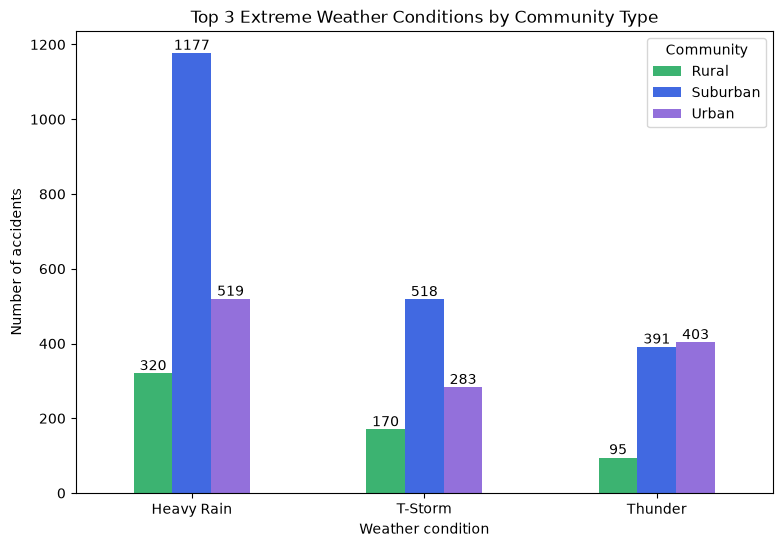

In [31]:
# Count accidents for each condition within each community
chart_data = pd.crosstab(extreme["Weather_Condition"], extreme["Community"])
chart_data = chart_data.loc[top3_names, ["Rural", "Suburban", "Urban"]]

# Grouped bar chart
ax = chart_data.plot(kind="bar", figsize=(9, 6), color=["mediumseagreen", "royalblue", "mediumpurple"])

for container in ax.containers:
    ax.bar_label(container)   # accident count 

plt.title("Top 3 Extreme Weather Conditions by Community Type")
plt.xlabel("Weather condition")
plt.ylabel("Number of accidents")
plt.xticks(rotation=0)
plt.legend(title="Community")
plt.show()

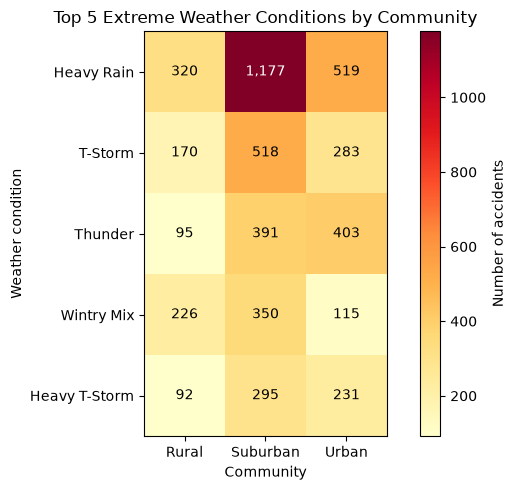

In [ ]:
# Top 5 extreme conditions overall
extreme = df[df["is_extreme"] & df["Community"].notna()]
top5_names = extreme["Weather_Condition"].value_counts().head(5).index

# Rows:conditions Columns: communities
by_community = pd.crosstab(extreme["Weather_Condition"], extreme["Community"])
data = by_community.loc[top5_names, ["Rural", "Suburban", "Urban"]]

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(data.values, cmap="YlOrRd")

# Labeling axes
ax.set_xticks(range(len(data.columns)))
ax.set_xticklabels(data.columns)
ax.set_yticks(range(len(data.index)))
ax.set_yticklabels(data.index)

# Accident cell
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        value = data.values[i, j]
        text_color = "white" if value > data.values.max() / 2 else "black"
        ax.text(j, i, f"{value:,}", ha="center", va="center", color=text_color)

ax.set_title("Top 5 Extreme Weather Conditions by Community")
ax.set_xlabel("Community")
ax.set_ylabel("Weather condition")
fig.colorbar(im, label="Number of accidents")
plt.tight_layout()
plt.show()